# 5. Таблицы и рисунки статьи

Все оценки считаются по `results/curves.csv`, `results/stability.csv` и `results/recovery.csv`. Правила
(разделы 4.5 и 6): T = 4…30 (на синтетике с 20 темами до 40); излом энергии и силуэт — на сетке каждой модели;
минимум медианы JS — на общих точках, где у RTM и LDA есть по три допустимых запуска; при равенстве берётся
меньшее T. Чтобы использовать свой пересчёт, укажите `RES = ROOT / "results" / "recomputed"`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [2]:
import pandas as pd
from rtm import summary as sm
from rtm.criteria import knee
from rtm.data import CORPORA, SYNTH, REAL, T_MIN, t_max

RES = ROOT / "results"
curves = pd.read_csv(RES / "curves.csv")
stability = pd.read_csv(RES / "stability.csv")
recovery = pd.read_csv(RES / "recovery.csv")
est = sm.estimates(curves, stability)
pd.set_option("display.width", 200, "display.max_columns", 30)

## Таблицы 11, 14 и 18 — оценки числа тем по трём признакам

In [3]:
est.pivot(index="corpus", columns="model", values=["energy", "js_lift", "silhouette"]).reindex(list(CORPORA))

energy                 js_lift                 silhouette                
model             ETM LDA ProdLDA RTM     ETM LDA ProdLDA RTM        ETM LDA ProdLDA RTM
corpus                                                                                  
synth_K6            6  12      16   6       6   5       5   6          5   5       6   6
synth_k            11  13       8  11      10  13       4  14         10  11      13  11
synth_K20          10  18       8  19       4  18       4  19         10  14      14  19
synth_K12_uneq     11  12      14  10      10  14       6  12          6   6      10  10
lenta_E2           12  11      12   8       8   6       4  12          6   6      11  10
news20_clean       18  18       8  10      20   6       6   8          6  10      18  10
livedoor           10  14      10  10       8   4       4  12          4   4       8   8
thucnews           10  12      10  18      14  10      12  16          6   6      10   8
gnad10             12  12      11   9       4   6       4  12          7   6       8  12
sanad              10   6       6   6       6   4       5   4          4   4       5   6
mnds                8  17       8   8      12  10       4   8         10  14       8  20

In [4]:
est[est.model.isin(["RTM", "LDA"])][["corpus", "K", "model", "energy", "energy_runs", "js_lift", "js_lift_bits",
                                       "silhouette", "silhouette_runs"]].round(3)

,corpus,K,model,energy,energy_runs,js_lift,js_lift_bits,silhouette,silhouette_runs
0,synth_K6,6,RTM,6,6/6/6,6,0.006,6,6/6/5
1,synth_K6,6,LDA,12,12/16/10,5,0.047,5,5/6/5
4,synth_k,12,RTM,11,12/11/11,14,0.013,11,12/11/11
5,synth_k,12,LDA,13,14/13/12,13,0.049,11,12/11/11
8,synth_K20,20,RTM,19,22/16/24,19,0.017,19,18/19/16
9,synth_K20,20,LDA,18,19/19/16,18,0.056,14,16/16/14
12,synth_K12_uneq,12,RTM,10,10/10/10,12,0.020,10,8/12/11
13,synth_K12_uneq,12,LDA,12,12/8/10,14,0.069,6,10/12/8
16,lenta_E2,10,RTM,8,9/8/8,12,0.097,10,10/8/12
17,lenta_E2,10,LDA,11,11/10/12,6,0.128,6,6/11/6


## Таблицы 12 и 19 — средняя ошибка |T* − K|

In [5]:
sm.mean_errors(est)

err_energy  err_js_lift  err_js_full  err_silhouette
corpora     model                                                        
all 11      RTM            2.82         3.36         3.55            2.55
            LDA            2.09         4.18         4.45            4.55
            ProdLDA        5.36         7.09         3.55            2.64
            ETM            3.27         3.09         4.00            5.64
synthetic 4 RTM            1.00         0.75         0.75            1.00
            LDA            2.25         1.50         1.25            3.50
            ProdLDA        7.00         7.75         2.25            2.25
            ETM            3.00         5.00         7.50            4.75
real 7      RTM            3.86         4.86         5.14            3.43
            LDA            2.00         5.71         6.29            5.14
            ProdLDA        4.43         6.71         4.29            2.86
            ETM            3.43         2.00         2.00            6.14

## Таблица 13 — точные попадания и ошибки не больше двух тем (33 оценки)

In [6]:
sm.hits(est)

,exact,within_2,n
model,,,
RTM,6,21,33
LDA,2,14,33
ProdLDA,1,16,33
ETM,4,17,33


## Таблица 20 — знаковый тест по корпусам

In [7]:
sm.sign_tests(est)

,against,criterion,RTM better,worse,ties,p
0,LDA,energy,4,5,2,1.000
1,LDA,js_lift,7,2,2,0.180
2,LDA,js_full,6,2,3,0.289
3,LDA,silhouette,7,0,4,0.016
4,ProdLDA,energy,5,0,6,0.062
5,ProdLDA,js_lift,9,1,1,0.021
6,ProdLDA,js_full,3,4,4,1.000
7,ProdLDA,silhouette,4,3,4,1.000
8,ETM,energy,3,2,6,1.000
9,ETM,js_lift,3,5,3,0.727


## Таблицы 16 и 17 — минимумы медианы JS у RTM и LDA в двух представлениях

In [8]:
t16 = est[est.model.isin(["RTM", "LDA"])].pivot(index="corpus", columns="model",
                                                values=["js_full", "js_full_bits", "js_lift", "js_lift_bits"])
display(t16.reindex(list(CORPORA)).round(3))
rows = []
for name, cs in (("все 11", list(CORPORA)), ("реальные 7", REAL), ("синтетика 4", SYNTH)):
    z = est[est.corpus.isin(cs)]
    for rep in ("full", "lift"):
        r = {"корпуса": name, "представление": rep}
        for m in ("RTM", "LDA"):
            e = z[z.model == m][f"err_js_{rep}"]
            r[f"MAE {m}"], r[f"ошибка ≤ 2 {m}"] = round(e.mean(), 2), f"{(e <= 2).sum()}/{len(e)}"
        rows.append(r)
pd.DataFrame(rows)

js_full       js_full_bits        js_lift       js_lift_bits       
model              LDA   RTM          LDA    RTM     LDA   RTM          LDA    RTM
corpus                                                                            
synth_K6           6.0   6.0        0.014  0.002     5.0   6.0        0.047  0.006
synth_k           11.0  14.0        0.016  0.004    13.0  14.0        0.049  0.013
synth_K20         22.0  19.0        0.019  0.005    18.0  19.0        0.056  0.017
synth_K12_uneq    14.0  12.0        0.030  0.006    14.0  12.0        0.069  0.020
lenta_E2           6.0  12.0        0.057  0.044     6.0  12.0        0.128  0.097
news20_clean       6.0   8.0        0.077  0.050     6.0   8.0        0.169  0.077
livedoor           4.0  14.0        0.122  0.073     4.0  12.0        0.194  0.123
thucnews          10.0  16.0        0.094  0.022    10.0  16.0        0.177  0.054
gnad10             8.0  12.0        0.133  0.025     6.0  12.0        0.258  0.065
sanad              4.0   4.0        0.022  0.001     4.0   4.0        0.046  0.002
mnds               4.0   8.0        0.127  0.018    10.0   8.0        0.306  0.053

,корпуса,представление,MAE RTM,ошибка ≤ 2 RTM,MAE LDA,ошибка ≤ 2 LDA
0,все 11,full,3.55,6/11,4.45,5/11
1,все 11,lift,3.36,6/11,4.18,4/11
2,реальные 7,full,5.14,2/7,6.29,1/7
3,реальные 7,lift,4.86,2/7,5.71,0/7
4,синтетика 4,full,0.75,4/4,1.25,4/4
5,синтетика 4,lift,0.75,4/4,1.50,4/4


## Таблицы 8, 10 и 15 — излом энергии и наклоны до и после него (RTM и LDA)

In [9]:
rows = []
for c in CORPORA:
    for m in ("RTM", "LDA"):
        x = curves[(curves.corpus == c) & (curves.model == m) & (curves["T"] >= T_MIN) & (curves["T"] <= t_max(c))]
        mean = x.groupby("T")["E"].mean()
        tk, a, b = knee(mean.index, mean.values)
        rows.append({"corpus": c, "model": m, "knee": int(tk), "slope before": round(a, 2), "slope after": round(b, 2)})
pd.DataFrame(rows)

,corpus,model,knee,slope before,slope after
0,synth_K6,RTM,6,-0.41,-0.03
1,synth_K6,LDA,12,-0.06,-0.02
2,synth_k,RTM,11,-0.37,-0.04
3,synth_k,LDA,13,-0.06,0.00
4,synth_K20,RTM,19,-0.39,-0.04
5,synth_K20,LDA,18,-0.06,0.03
6,synth_K12_uneq,RTM,10,-0.40,0.02
7,synth_K12_uneq,LDA,12,-0.05,-0.01
8,lenta_E2,RTM,8,-0.37,-0.25
9,lenta_E2,LDA,11,-0.08,-0.03


## Таблица 5 — восстановление истинных тем на синтетике

In [10]:
rows = []
for c in SYNTH:
    K = CORPORA[c][1]
    for m in ("RTM", "LDA"):
        x = recovery[(recovery.corpus == c) & (recovery.model == m)]
        tk = int(est[(est.corpus == c) & (est.model == m)]["energy"].iloc[0])
        at = lambda T: "/".join(map(str, x[x["T"] == T].sort_values("seed")["found"]))
        mean = x.groupby("T")["found"].mean()
        rows.append({"corpus": c, "K": K, "model": m, "found at T = K": at(K), "energy knee": tk,
                     "found at knee": at(tk), "max of mean": round(mean.max(), 1), "at T": int(mean.idxmax())})
pd.DataFrame(rows)

,corpus,K,model,found at T = K,energy knee,found at knee,max of mean,at T
0,synth_K6,6,RTM,6/6/6,6,6/6/6,6.0,6
1,synth_K6,6,LDA,4/6/6,12,5/4/5,5.3,6
2,synth_k,12,RTM,12/10/10,11,10/10/10,12.0,14
3,synth_k,12,LDA,12/9/10,13,8/11/12,11.0,16
4,synth_K20,20,RTM,17/15/16,19,18/16/18,20.0,32
5,synth_K20,20,LDA,18/14/14,18,16/13/16,19.0,24
6,synth_K12_uneq,12,RTM,10/10/10,10,8/8/8,12.0,20
7,synth_K12_uneq,12,LDA,6/7/7,12,6/7/7,8.7,14


## Рисунки 8–9 — три признака в зависимости от T

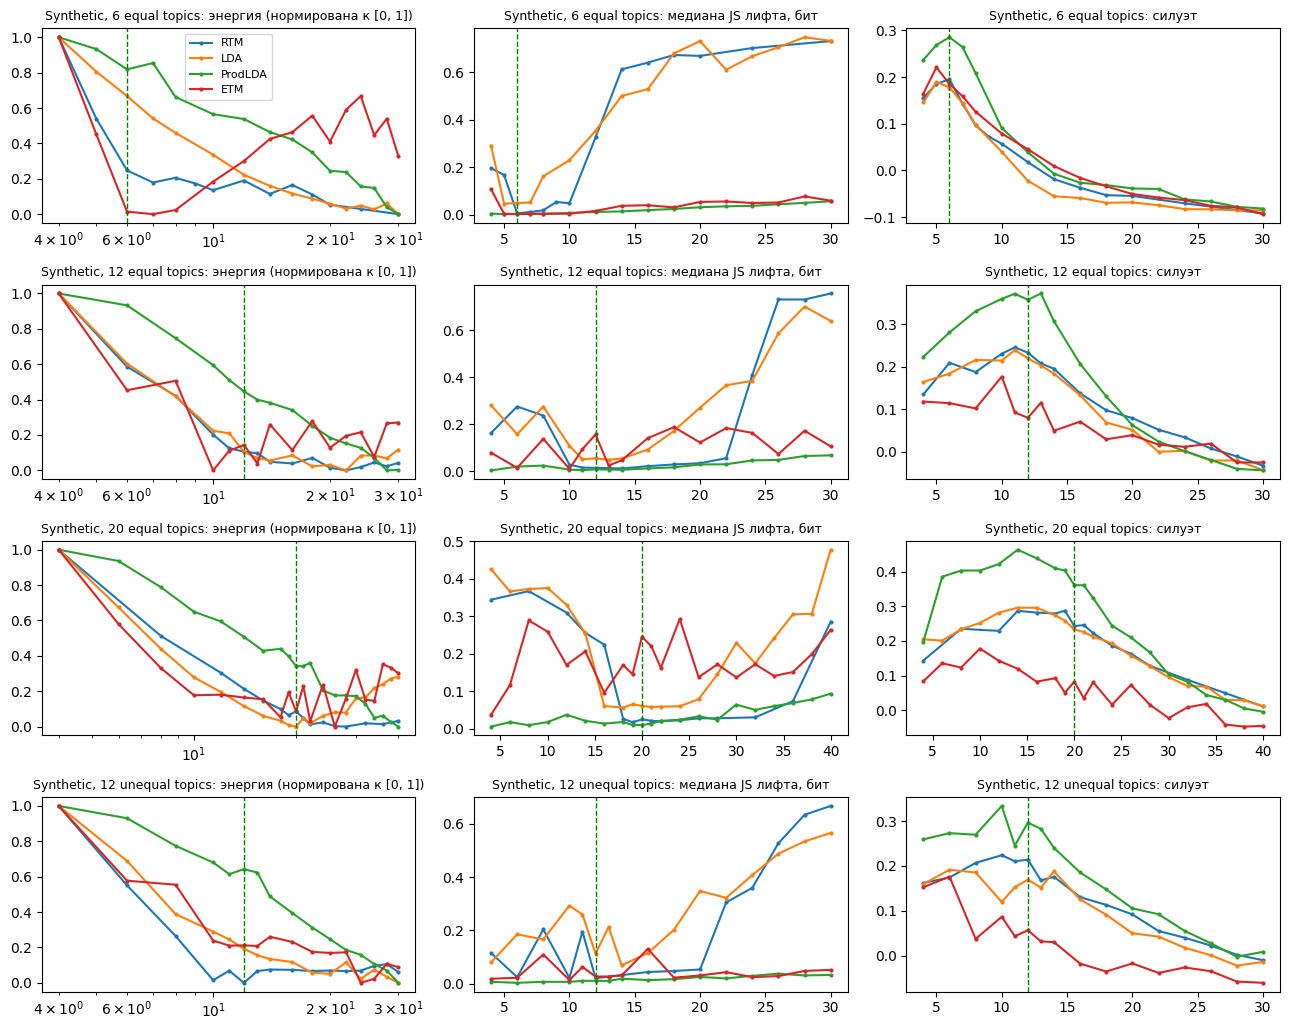

In [11]:
import matplotlib.pyplot as plt

def plot(corpora):
    fig, axes = plt.subplots(len(corpora), 3, figsize=(13, 2.6 * len(corpora)), squeeze=False)
    for i, c in enumerate(corpora):
        K = CORPORA[c][1]
        for m, col in (("RTM", "tab:blue"), ("LDA", "tab:orange"), ("ProdLDA", "tab:green"), ("ETM", "tab:red")):
            x = curves[(curves.corpus == c) & (curves.model == m) & (curves["T"].between(T_MIN, t_max(c)))]
            e = x.groupby("T")["E"].mean()
            axes[i, 0].plot(e.index, (e - e.min()) / (e.max() - e.min()), "o-", ms=2, color=col, label=m)
            s = stability[(stability.corpus == c) & (stability.model == m) & (stability.representation == "lift")]
            axes[i, 1].plot(s["T"], s["median_JS"], "o-", ms=2, color=col)
            g = x.groupby("T")["silhouette"].mean()
            axes[i, 2].plot(g.index, g.values, "o-", ms=2, color=col)
        for j, t in enumerate(("энергия (нормирована к [0, 1])", "медиана JS лифта, бит", "силуэт")):
            axes[i, j].axvline(K, color="green", ls="--", lw=1)
            axes[i, j].set_title(f"{CORPORA[c][0]}: {t}", fontsize=9)
            axes[i, j].set_xscale("log" if j == 0 else "linear")
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()

plot(SYNTH)

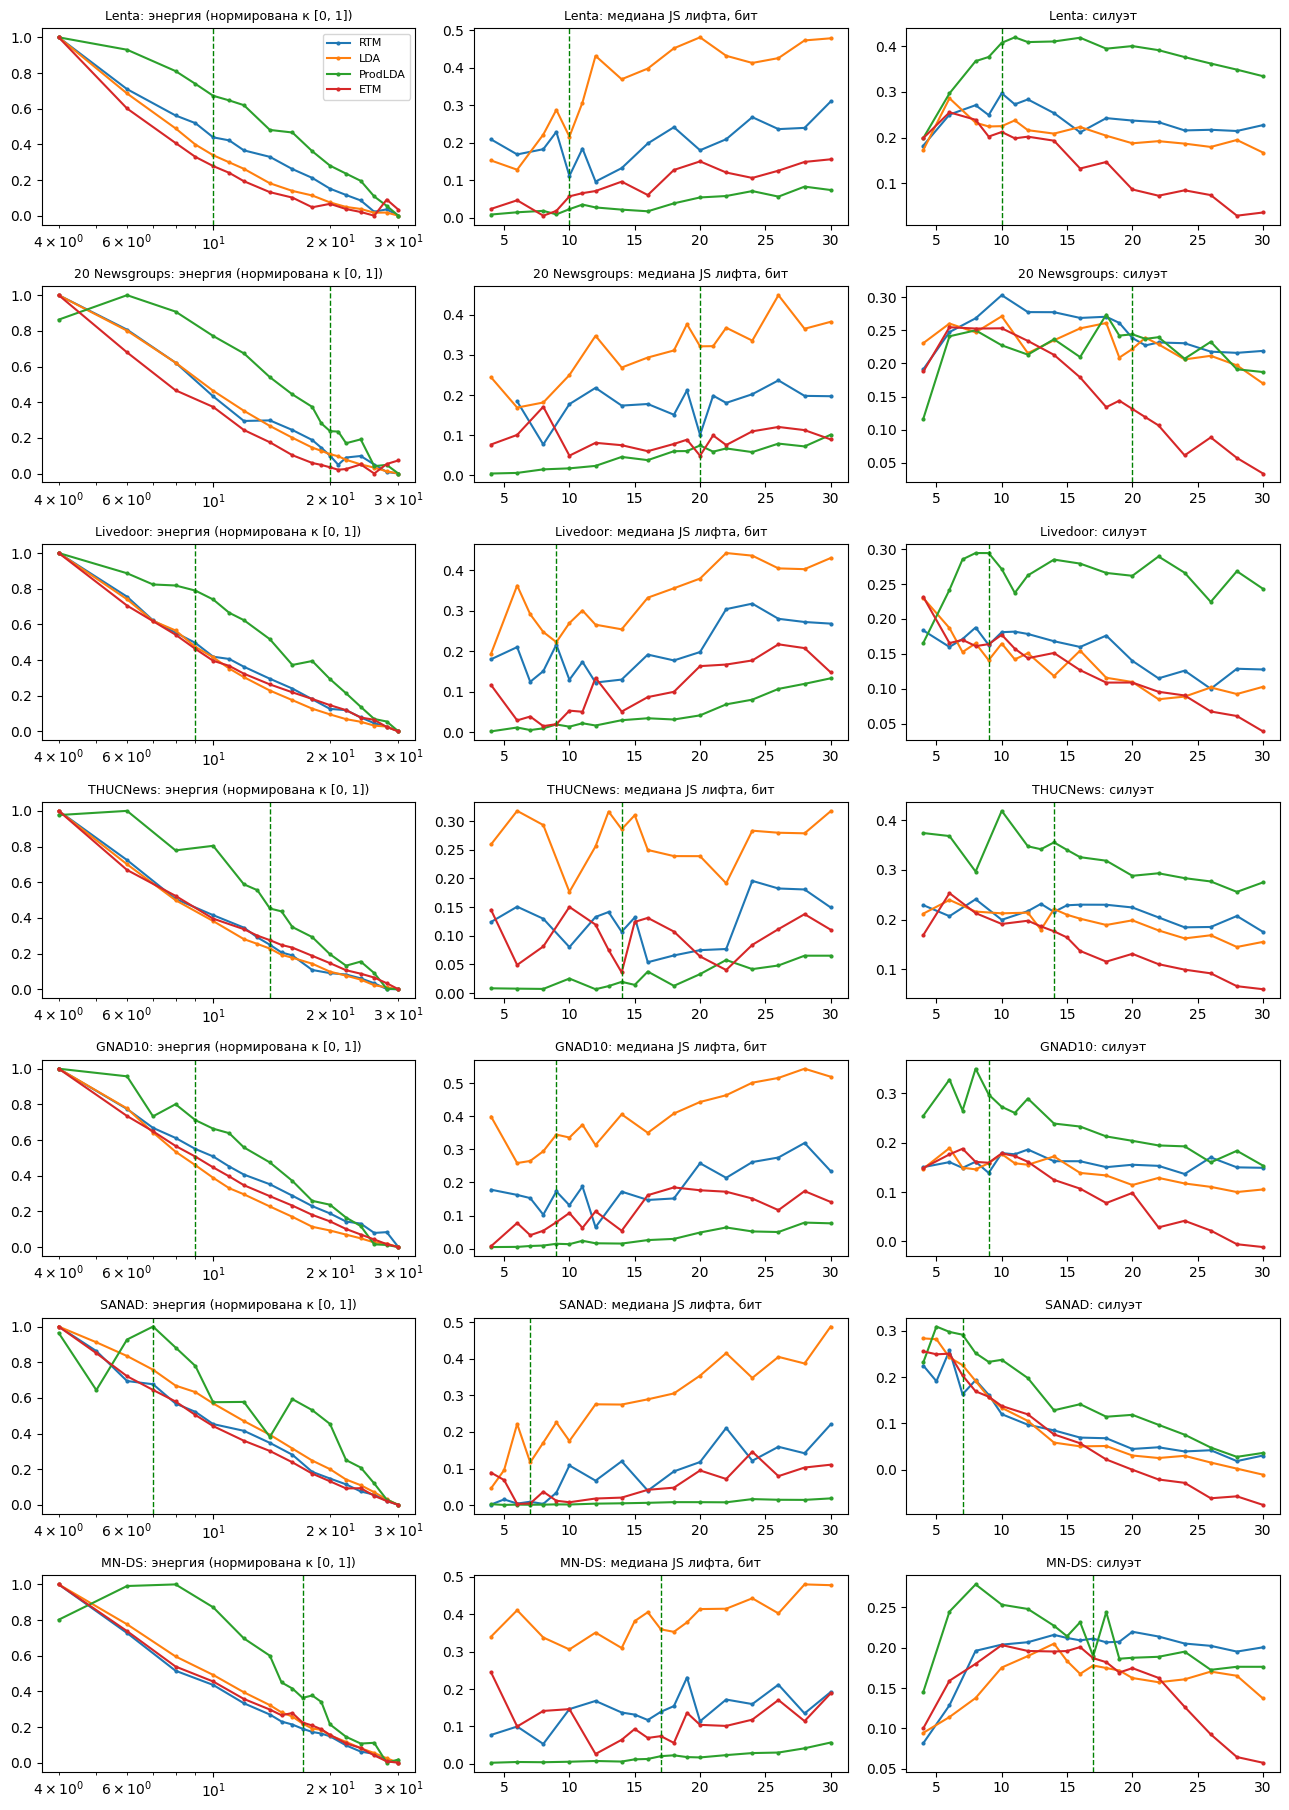

In [12]:
plot(REAL)